# Egypt Food Price Analysis (WFP Data)

Monthly retail food prices in Egypt, 2010–2026, from WFP (`wfp_food_prices_egy.csv` + `wfp_markets_egy.csv`).
Two series: **National Average** and **Cairo**.

# 1. Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import scipy.stats as stats
import statsmodels.api as sm
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# 2. Load Dataset

In [5]:
df = pd.read_csv('wfp_food_prices_egy.csv')
df_markets = pd.read_csv('wfp_markets_egy.csv')

print(f"Food prices file: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Markets file: {df_markets.shape[0]} rows, {df_markets.shape[1]} columns")

Food prices file: 3647 rows, 16 columns
Markets file: 68 rows, 7 columns


# 3. Data Understanding

In [26]:
df.head()

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2010-08-15,NaN,NaN,National Average,226,NaN,NaN,cereals and tubers,Pasta,112,KG,actual,Retail,EGP,4.70,0.82
1,2010-08-15,NaN,NaN,National Average,226,NaN,NaN,cereals and tubers,Potatoes,83,KG,actual,Retail,EGP,1.81,0.32
2,2010-08-15,NaN,NaN,National Average,226,NaN,NaN,cereals and tubers,Rice,52,KG,actual,Retail,EGP,3.98,0.70
3,2010-08-15,NaN,NaN,National Average,226,NaN,NaN,cereals and tubers,Wheat flour,58,KG,actual,Retail,EGP,3.44,0.60
4,2010-08-15,NaN,NaN,National Average,226,NaN,NaN,"meat, fish and eggs",Meat (beef),141,KG,actual,Retail,EGP,50.22,8.81


In [27]:
df.dtypes # Date Type Is not Correct

date             object
admin1           object
admin2           object
market           object
market_id         int64
latitude        float64
longitude       float64
category         object
commodity        object
commodity_id      int64
unit             object
priceflag        object
pricetype        object
currency         object
price           float64
usdprice        float64
dtype: object

In [6]:
df.info() # looking for null Values

<class 'pandas.DataFrame'>
RangeIndex: 3647 entries, 0 to 3646
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          3647 non-null   str    
 1   admin1        1049 non-null   str    
 2   admin2        1049 non-null   str    
 3   market        3647 non-null   str    
 4   market_id     3647 non-null   int64  
 5   latitude      1049 non-null   float64
 6   longitude     1049 non-null   float64
 7   category      3647 non-null   str    
 8   commodity     3647 non-null   str    
 9   commodity_id  3647 non-null   int64  
 10  unit          3647 non-null   str    
 11  priceflag     3647 non-null   str    
 12  pricetype     3647 non-null   str    
 13  currency      3647 non-null   str    
 14  price         3647 non-null   float64
 15  usdprice      3647 non-null   float64
dtypes: float64(4), int64(2), str(10)
memory usage: 456.0 KB


In [8]:
df.isna().sum() #The 4 columns has the same num of Nulls => will be a Relation

date               0
admin1          2598
admin2          2598
market             0
market_id          0
latitude        2598
longitude       2598
category           0
commodity          0
commodity_id       0
unit               0
priceflag          0
pricetype          0
currency           0
price              0
usdprice           0
year               0
month              0
dtype: int64

# 4. Cleaning Data

**Fix types, derive year/month**

In [7]:
df['date'] = pd.to_datetime(df['date'], errors='coerce') # update the type of date
df['year'] = df['date'].dt.year # 
df['month'] = df['date'].dt.month #
print(df.head())

        date admin1 admin2            market  market_id  latitude  longitude  \
0 2010-08-15    NaN    NaN  National Average        226       NaN        NaN   
1 2010-08-15    NaN    NaN  National Average        226       NaN        NaN   
2 2010-08-15    NaN    NaN  National Average        226       NaN        NaN   
3 2010-08-15    NaN    NaN  National Average        226       NaN        NaN   
4 2010-08-15    NaN    NaN  National Average        226       NaN        NaN   

              category    commodity  commodity_id unit priceflag pricetype  \
0   cereals and tubers        Pasta           112   KG    actual    Retail   
1   cereals and tubers     Potatoes            83   KG    actual    Retail   
2   cereals and tubers         Rice            52   KG    actual    Retail   
3   cereals and tubers  Wheat flour            58   KG    actual    Retail   
4  meat, fish and eggs  Meat (beef)           141   KG    actual    Retail   

  currency  price  usdprice  year  month  
0      

**Fill `admin1`/`admin2` with `National`** — confirmed above these nulls = the National series, not random gaps.

In [9]:
# Fill missing values (NaN) in admin1 (governorate) column with 'National'
df['admin1'] = df['admin1'].fillna('National')
# Fill missing values (NaN) in admin2 (district) column with 'National'
df['admin2'] = df['admin2'].fillna('National') 
# Ensure 'price' column is strictly float and convert any unexpected non-numeric values to NaN
df['price'] = pd.to_numeric(df['price'], errors='coerce') 
# Ensure 'usdprice' column is strictly float and convert any unexpected non-numeric values to NaN
df['usdprice'] = pd.to_numeric(df['usdprice'], errors='coerce')


**Check which columns are actually constant before dropping them**

In [10]:
Cols =['unit' , 'priceflag' , 'pricetype' , 'currency'] 
for i in Cols:
    print()
    print(df[i].unique()) # all Values is the same so will not make an effect except --unit--



<StringArray>
['KG', '800 G', 'Unit', '8 pcs', 'L', '1 piece']
Length: 6, dtype: str

<StringArray>
['actual']
Length: 1, dtype: str

<StringArray>
['Retail']
Length: 1, dtype: str

<StringArray>
['EGP']
Length: 1, dtype: str


In [11]:
df.isna().sum() # Clean now with values which will make a real effect

date               0
admin1             0
admin2             0
market             0
market_id          0
latitude        2598
longitude       2598
category           0
commodity          0
commodity_id       0
unit               0
priceflag          0
pricetype          0
currency           0
price              0
usdprice           0
year               0
month              0
dtype: int64

In [12]:
df['admin1'].unique() # make sure from the 2 values in admin1 (National) means the other Governates of Egypt as a Total Average
df['admin2'].unique()  # abdin is the default values to cairo
df['commodity'].unique() #take a look on Comodity Values

<StringArray>
[                           'Pasta',                         'Potatoes',
                             'Rice',                      'Wheat flour',
                      'Meat (beef)',           'Meat (chicken, frozen)',
                            'Sugar',                'Ghee (artificial)',
                   'Ghee (natural)',                      'Oil (maize)',
                'Beans (fava, dry)',                          'Lentils',
                           'Garlic',                     'Onions (red)',
                   'Onions (white)',                         'Tomatoes',
                             'Eggs',                  'Oil (sunflower)',
                   'Fish (tilapia)',       'Meat (beef, without bones)',
                           'Cheese',                   'Cheese (picon)',
                             'Milk',                      'Oil (mixed)',
      'Wheat flour (unpacked, 72%)',               'Eggs (medium size)',
             'Meat (chicken, farm)', 

**Merge with markets file** — check `market_id` is unique first, so the merge can't duplicate rows.

In [13]:
df_markets = pd.read_csv('wfp_markets_egy.csv') # read the Sec. File
df_final = pd.merge(df, df_markets, on='market_id', how='left', suffixes=('', '_info')) # merge the 2 files

print(f"Rows After merge: {df_final.shape[0]}")
print(f"Columns After merge: {df_final.shape[1]}")

Rows After merge: 3647
Columns After merge: 24


In [14]:
df_final.head(10)

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,...,price,usdprice,year,month,market_info,countryiso3,admin1_info,admin2_info,latitude_info,longitude_info
0,2010-08-15,National,National,National Average,226,NaN,NaN,cereals and tubers,Pasta,112,...,4.70,0.82,2010,8,National Average,EGY,NaN,NaN,NaN,NaN
1,2010-08-15,National,National,National Average,226,NaN,NaN,cereals and tubers,Potatoes,83,...,1.81,0.32,2010,8,National Average,EGY,NaN,NaN,NaN,NaN
2,2010-08-15,National,National,National Average,226,NaN,NaN,cereals and tubers,Rice,52,...,3.98,0.70,2010,8,National Average,EGY,NaN,NaN,NaN,NaN
3,2010-08-15,National,National,National Average,226,NaN,NaN,cereals and tubers,Wheat flour,58,...,3.44,0.60,2010,8,National Average,EGY,NaN,NaN,NaN,NaN
4,2010-08-15,National,National,National Average,226,NaN,NaN,"meat, fish and eggs",Meat (beef),141,...,50.22,8.81,2010,8,National Average,EGY,NaN,NaN,NaN,NaN
5,2010-08-15,National,National,National Average,226,NaN,NaN,"meat, fish and eggs","Meat (chicken, frozen)",207,...,17.00,2.98,2010,8,National Average,EGY,NaN,NaN,NaN,NaN
6,2010-08-15,National,National,National Average,226,NaN,NaN,miscellaneous food,Sugar,97,...,4.28,0.75,2010,8,National Average,EGY,NaN,NaN,NaN,NaN
7,2010-08-15,National,National,National Average,226,NaN,NaN,oil and fats,Ghee (artificial),106,...,9.82,1.72,2010,8,National Average,EGY,NaN,NaN,NaN,NaN
8,2010-08-15,National,National,National Average,226,NaN,NaN,oil and fats,Ghee (natural),107,...,33.42,5.86,2010,8,National Average,EGY,NaN,NaN,NaN,NaN
9,2010-08-15,National,National,National Average,226,NaN,NaN,oil and fats,Oil (maize),362,...,8.76,1.54,2010,8,National Average,EGY,NaN,NaN,NaN,NaN


In [15]:
df_final['market_info'].unique() # not additional values

<StringArray>
['National Average', 'Cairo (national average)']
Length: 2, dtype: str

In [16]:
df_final['market_id'].unique() #from the head and tail => (226 = National) and (10254 = cairo)

array([  226, 10254])

In [17]:
search = ['admin1_info','admin2_info','latitude','longitude'] 
for col in search :
    print(df_final[col].unique())  # in latitude and longitude 30.05 : 31.24 are constant values for Cairo Zone and Null is for National so we will delete them and take admin1 as a primary common

<StringArray>
[nan, 'Cairo']
Length: 2, dtype: str
<StringArray>
[nan, 'Abdin']
Length: 2, dtype: str
[  nan 30.05]
[  nan 31.24]


In [18]:
cdf_final = df_final[['date','admin1','admin2','market','market_id','market_info','category','commodity','unit','price','usdprice']].copy()
# admin1_info and admin2_info has the same values of admin1 and admin2 so admin1 and admin2 can replace them 
# market info

In [19]:
cdf_final.isna().sum() # clean 

date           0
admin1         0
admin2         0
market         0
market_id      0
market_info    0
category       0
commodity      0
unit           0
price          0
usdprice       0
dtype: int64

# 5.Data Manipulation

###  Creating a safe copy for manipulation

In [20]:
df_manipulated = cdf_final.copy()

specific columns for better readability

### Creating new calculated columns using apply() and lambda function

In [21]:
cdf_final['implied_fx_rate'] = cdf_final['price'] / cdf_final['usdprice']

### Groupby and aggregation for summary statistics

# Categorization & Mapping

In [23]:
commodity_categories = {
    "Meat (beef)": "Meat & Poultry",
    "Meat (buffalo)": "Meat & Poultry",
    "Meat (beef, without bones)": "Meat & Poultry",
    "Meat (chicken, frozen)": "Meat & Poultry",
    "Meat (chicken, farm)": "Meat & Poultry",
    "Beans (fava, dry)": "Legumes & Pulses",
    "Beans (green)": "Vegetables",
    "Beans (kidney)": "Legumes & Pulses",
    "Lentils": "Legumes & Pulses",
    "Rice": "Grains & Cereals",
    "Pasta": "Grains & Cereals",
    "Wheat flour": "Grains & Cereals",
    "Wheat flour (unpacked, 72%)": "Grains & Cereals",
    "Sugar": "Groceries & Staples",
    "Potatoes": "Vegetables",
    "Tomatoes": "Vegetables",
    "Onions": "Vegetables",
    "Onions (red)": "Vegetables",
    "Onions (white)": "Vegetables",
    "Garlic": "Vegetables",
    "Cucumbers (medium sized)": "Vegetables",
    "Arugula": "Vegetables",
    "Eggplants": "Vegetables",
    "Oranges": "Fruits",
    "Melons (cantaloupe)": "Fruits",
    "Eggs": "Dairy & Eggs",
    "Eggs (medium size)": "Dairy & Eggs",
    "Milk": "Dairy & Eggs",
    "Milk (fresh)": "Dairy & Eggs",
    "Cheese": "Dairy & Eggs",
    "Cheese (picon)": "Dairy & Eggs",
    "Cheese (local, processed, Nesto)": "Dairy & Eggs",
    "Cheese (local, Koreish)": "Dairy & Eggs",
    "Ghee (artificial)": "Oils & Fats",
    "Ghee (natural)": "Oils & Fats",
    "Oil (maize)": "Oils & Fats",
    "Oil (sunflower)": "Oils & Fats",
    "Oil (mixed)": "Oils & Fats",
    "Oil (cotton)": "Oils & Fats",
    "Fish (tilapia)": "Fish & Seafood"
}

df_manipulated['food_category'] = df_manipulated['commodity'].map(commodity_categories)

print(df_manipulated['food_category'].value_counts(dropna=False))

food_category
Vegetables             844
Grains & Cereals       609
Oils & Fats            584
Dairy & Eggs           501
Legumes & Pulses       441
Meat & Poultry         375
Groceries & Staples    208
Fish & Seafood          66
Fruits                  19
Name: count, dtype: int64


# 6.Descriptive Statistics

In [26]:
cdf_final.describe()

,date,market_id,price,usdprice,implied_fx_rate
count,3647,3647.000000,3647.000000,3647.000000,3647.000000
mean,2018-12-21 09:21:51.872772,3110.390458,25.239191,1.545912,18.966538
min,2010-08-15 00:00:00,226.000000,0.660000,0.064000,5.636364
25%,2015-04-15 00:00:00,226.000000,6.600000,0.500000,7.630013
50%,2019-05-15 00:00:00,226.000000,14.010000,0.880000,15.753846
75%,2022-05-30 12:00:00,10254.000000,28.500000,1.700000,18.728501
max,2026-07-15 00:00:00,10254.000000,302.100000,11.670000,53.571429
std,NaN,4539.891032,33.468842,1.955180,13.848512


In [29]:
## Right-Skewed Distribution: Mean (25.24) > Median (14.01) indicating a few highly-priced items pull the average up
## Broad Timeframe: Data spans 16 years (2010 to 2026), capturing long-term inflation and economic shifts.
## Exchange Rate Impact: The disparity between max EGP price (302.10) and max USD price (11.67) highlights currency devaluation over time.

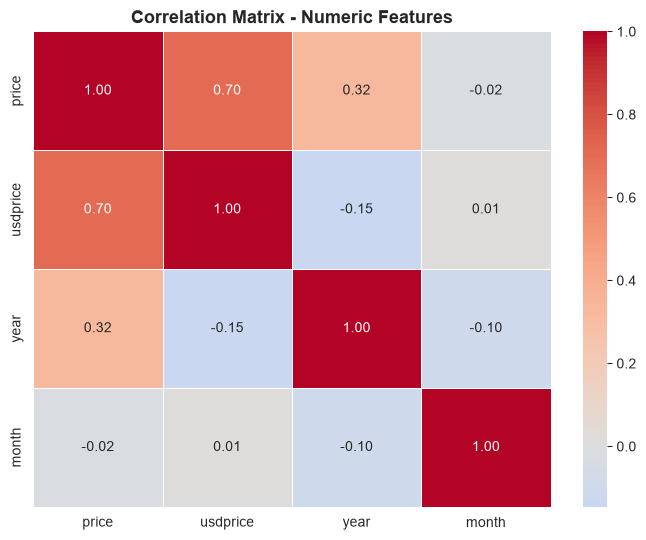

In [27]:
df_final['year'] = df_final['date'].dt.year
df_final['month'] = df_final['date'].dt.month
numeric_cols = ['price', 'usdprice', 'year', 'month']
corr_matrix = df_final[numeric_cols].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, linecolor='white')
plt.title('Correlation Matrix - Numeric Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


The negative correlation (-0.15) between 'year' and 'usdprice' alongside a positive correlation (0.32) with 'price' confirms continuous local currency devaluation.
Future budgets for imports must be hedged against the USD, as the local currency trend is strictly inflationary over time.

###  Time-Series Data

In [ ]:
import scipy.stats as stats
import numpy as np
def analyze_yearly_prices(data):
    n = len(data)
    mean = data.mean()
        if n > 1:
        se = data.std() / np.sqrt(n)
        ci = stats.t.interval(0.95, df=n-1, loc=mean, scale=se)
        lower_mean, upper_mean = ci[0], ci[1]
    else:
        lower_mean, upper_mean = mean, mean
        
    return pd.Series({
        'Min_Price': data.min(),           
        'Lower_Mean': lower_mean,          
        'Actual_Mean': mean,               
        'Upper_Mean': upper_mean,        
        'Max_Price (Meat)': data.max()     
    })

yearly_stats = cdf_final.dropna(subset=['price']).groupby('year')['price'].apply(analyze_yearly_prices).unstack().round(2)

yearly_stats = yearly_stats[['Min_Price', 'Lower_Mean', 'Actual_Mean', 'Upper_Mean', 'Max_Price (Meat)']]

print("--- Detailed Price Range & Mean Interval Per Year ---")
display(yearly_stats)

--- Detailed Price Range & Mean Interval Per Year ---


,Min_Price,Lower_Mean,Actual_Mean,Upper_Mean,Max_Price (Meat)
year,,,,,
2010,1.53,8.13,11.17,14.22,57.02
2011,1.40,9.58,11.63,13.68,60.40
2012,1.65,10.11,12.24,14.38,61.10
2013,0.66,10.43,12.46,14.49,62.38
2014,0.68,10.55,12.73,14.92,67.50
2015,0.80,11.44,13.94,16.44,91.40
2016,0.95,15.08,18.32,21.56,114.00
2017,1.37,21.41,25.78,30.14,150.00
2018,1.56,21.67,26.26,30.84,149.09


# Feature engineering


### Price Segmentation (Tiers based on Quantiles)

In [33]:
Q1 = cdf_final['price'].quantile(0.25)
Q3 = cdf_final['price'].quantile(0.75)
conditions = [
    (cdf_final['price'] <= Q1),
    (cdf_final['price'] > Q1) & (cdf_final['price'] <= Q3),
    (cdf_final['price'] > Q3)
]
choices = ['Low Tier', 'Medium Tier', 'High Tier']
cdf_final['price_segment'] = np.select(conditions, choices, default='Unknown')
print("Distribution of Price Segments:")
print(cdf_final['price_segment'].value_counts())
print("-" * 50)
display(cdf_final[['commodity', 'price', 'price_segment']].sample(10))


Distribution of Price Segments:
price_segment
Medium Tier    1829
Low Tier        915
High Tier       903
Name: count, dtype: int64
--------------------------------------------------


,commodity,price,price_segment
1930,Oil (maize),28.46,Medium Tier
738,Sugar,6.04,Low Tier
2797,"Beans (fava, dry)",25.44,Medium Tier
2481,Cheese,29.73,High Tier
1383,Oil (mixed),20.50,Medium Tier
286,Pasta,5.00,Low Tier
3033,Oil (cotton),46.45,High Tier
813,Onions (red),3.34,Low Tier
1480,Lentils,21.65,Medium Tier
2214,Potatoes,3.27,Low Tier


# 7.Statistical Analysis

### Chi-Square Test: Categorical features vs Price Segments

In [35]:
cdf_final['month'] = pd.to_datetime(cdf_final['date'], errors='coerce').dt.month
cdf_final['price_segment'] = pd.qcut(cdf_final['price'].dropna(), q=3, labels=['Low', 'Medium', 'High'])
features_to_test = ['category', 'admin1', 'unit', 'month']

print("--- Chi-Square Test Results ---")
for feature in features_to_test:
    valid_data = cdf_final.dropna(subset=[feature, 'price_segment']) 
    contingency = pd.crosstab(valid_data[feature], valid_data['price_segment'])
    chi2, p_val, dof, expected = stats.chi2_contingency(contingency)
    significance = "Significant (p < 0.05)" if p_val < 0.05 else "Not significant"
    print(f"{feature:15s} | chi2 = {chi2:8.2f} | p = {p_val:.4f} -> {significance}")

--- Chi-Square Test Results ---
category        | chi2 =  1480.48 | p = 0.0000 -> Significant (p < 0.05)
admin1          | chi2 =   377.68 | p = 0.0000 -> Significant (p < 0.05)
unit            | chi2 =   580.63 | p = 0.0000 -> Significant (p < 0.05)
month           | chi2 =     5.59 | p = 0.9998 -> Not significant


Strong Price Drivers: The geographic location (admin1), the type of food (category), and the measurement unit have a statistically significant relationship (p < 0.05) with the price segment (Low/Medium/High). This confirms that regional economic differences and commodity types strongly dictate price brackets.

### Price Changes & Percentage Changes over time


In [52]:
cdf_final['food_category'] = cdf_final['commodity'].map(commodity_categories)
cat_inflation_summary = []
for cat, group in cdf_final.groupby('food_category'):
    valid = group.dropna(subset=['price'])
    start_data = valid[valid['year'] == 2010]
    end_data = valid[valid['year'] == 2026]
    if len(start_data) > 0 and len(end_data) > 0:
        price_start = start_data['price'].mean()
        price_end = end_data['price'].mean()
        if price_start > 0:
            years = 2026 - 2010
            cagr = ((price_end / price_start) ** (1 / years) - 1) * 100

            cat_inflation_summary.append({
                'Category': cat,
                'معدل الزيادة السنوي': cagr
            })
df_cat_final = pd.DataFrame(cat_inflation_summary)

df_cat_final = df_cat_final.sort_values(
    by='معدل الزيادة السنوي',
    ascending=False
)

df_cat_final['معدل الزيادة السنوي'] = (
    df_cat_final['معدل الزيادة السنوي']
    .map(lambda x: f"{x:+.1f}%")
)

display(df_cat_final.reset_index(drop=True))

,Category,معدل الزيادة السنوي
0,Groceries & Staples,+15.2%
1,Legumes & Pulses,+14.3%
2,Grains & Cereals,+12.0%
3,Meat & Poultry,+11.5%
4,Vegetables,+10.2%
5,Oils & Fats,+8.1%
